# 04_baseline — Model ladder (naive → recency → LogReg → boosted trees)

Per spec §5: a fair, escalating baseline **before** the GRU. All fitting (scaler / encoder / top-k country / impute / **feature-set selection**) uses **train (+val for selection) only**; **test is scored once**.

Evaluation axis = **temporal** (primary; deployment/forecast scenario). Frozen split from 03. Metric suite: ROC-AUC, PR-AUC (vs prevalence), P/R/F1, confusion, Precision@k / Recall@k / Lift@k, Brier, LogLoss, ECE + calibration.

> 2026-07-03 update (post independent re-review): (a) removed two exactly-duplicate columns (`history_purchase_count`==`frequency_total`, `is_uk`==`cty_United Kingdom`); (b) added a **val-based geography ablation** — is_uk-only vs is_uk+top-k country dummies — the rare-country dummies did not improve val, so they are dropped (UK-vs-non-UK is the only stable geographic signal at ~92% UK); (c) UK-model scope caveat added. F1/P/R below are at threshold **0.5 (provisional)** — spec §6 says the operating point must be fit on val; that is deferred to the calibration step, so model comparison here rests on ROC/PR/Lift@k/Brier.


## Setup + load frozen panel


In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from ds_common import *
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score,
    f1_score, confusion_matrix, brier_score_loss, log_loss)
import matplotlib.pyplot as plt
np.random.seed(RANDOM_SEED)
import sklearn; print("VERSIONS pandas",pd.__version__,"| numpy",np.__version__,"| sklearn",sklearn.__version__)
panel=load_features(); TARGET="churn"
print("panel",panel.shape,"| splits",panel["split"].value_counts().to_dict())
print("prevalence by split:",panel.groupby("split")[TARGET].mean().round(4).to_dict())


VERSIONS pandas 2.2.3 | numpy 2.1.3 | sklearn 1.6.1
loaded features_tabular.pkl: 47,933 rows x 39 cols | saved 2026-07-03 21:45
panel (47933, 39) | splits {'train': 23987, 'test': 13961, 'val': 9985}
prevalence by split: {'test': 0.4693, 'train': 0.5025, 'val': 0.5804}


## Feature assembly (deduplicated)

Numeric features from 03 **no longer contains `history_purchase_count`** (dropped at the 03 source; it equalled `frequency_total`). Geography: `is_uk` (kept) + candidate top-k country dummies fit **on train only**; `cty_United Kingdom` is dropped because it equals `is_uk`. `days_since_last_return` is NaN for no-return customers — trees keep NaN; the LogReg matrix imputes with the train median (`has_return_history` carries the missingness).


In [2]:
meta=[KEY,"cutoff","label_window_end","split","churn","country","max_purchase_time_used","max_return_time_used"]
num=[c for c in panel.columns if c not in meta]
num=[c for c in num if c!="history_purchase_count"]                 # guard: dropped at 03 source (was == frequency_total)
num=[c for c in num if not c.startswith("abl_")]                    # F4 candidates: excluded from main model, used only in the ablation cell
tr=panel["split"]=="train"; va=panel["split"]=="val"; te=panel["split"]=="test"
TOPK=5
topc=panel.loc[tr,"country"].value_counts().head(TOPK).index.tolist()   # train-fit
panel["country_group"]=np.where(panel["country"].isin(topc),panel["country"],"Other")
cg=pd.get_dummies(panel["country_group"],prefix="cty").astype(int)
cg=cg[[c for c in cg.columns if c not in ("cty_Other","cty_United Kingdom")]]  # drop Other ref + UK(==is_uk)
DUMMIES=list(cg.columns)
y=panel[TARGET].values
# skew list for log1p (LogReg only)
SKEW=["frequency_total","gross_monetary_total","gross_quantity_total","matched_val","matched_qty",
      "unmatched_qty","return_count","net_monetary_total","net_quantity_total",
      "freq_30d","freq_90d","freq_180d","gross_monetary_30d","gross_monetary_90d","gross_monetary_180d",
      "recency_days","tenure_days","days_since_last_return","fully_returned_order_count"]
print("num features (dedup):",len(num),"| candidate country dummies:",DUMMIES)
print("geography share -> is_uk %.1f%% | non-UK rows %d / customers %d"%(
    100*panel["is_uk"].mean(),(panel["is_uk"]==0).sum(),panel.loc[panel["is_uk"]==0,KEY].nunique()))


num features (dedup): 31 | candidate country dummies: ['cty_France', 'cty_Germany', 'cty_Netherlands', 'cty_Spain']
geography share -> is_uk 91.7% | non-UK rows 3990 / customers 451


## Geography ablation on VAL (decide whether rare-country dummies earn their keep)

At ~92% UK, `is_uk` may carry all usable geographic signal. Fit LogReg + boosted on train, score on **val** for two feature sets: **A = is_uk only** vs **B = is_uk + top-k dummies**. Keep the dummies only if they give LogReg a real val PR-AUC gain (>0.002) without hurting ROC; otherwise collapse the tail (use is_uk alone).


In [3]:
def build_X(use_dummies):
    return pd.concat([panel[num],cg],axis=1) if use_dummies else panel[num].copy()
def lr_prep_factory(Xtr):
    med=Xtr["days_since_last_return"].median()
    def prep(d):
        d=d.copy(); d["days_since_last_return"]=d["days_since_last_return"].fillna(med)
        for c in SKEW:
            if c in d: d[c]=np.log1p(d[c].clip(lower=0))
        return d
    return prep,med
def fit_eval_val(use_dummies):
    X=build_X(use_dummies); Xtr,Xva=X[tr],X[va]
    prep,_=lr_prep_factory(Xtr); sc=StandardScaler().fit(prep(Xtr).values)
    lr=LogisticRegression(max_iter=2000,random_state=RANDOM_SEED).fit(sc.transform(prep(Xtr).values),y[tr])
    plr=lr.predict_proba(sc.transform(prep(Xva).values))[:,1]
    try:
        from xgboost import XGBClassifier
        gb=XGBClassifier(n_estimators=400,max_depth=5,learning_rate=0.05,subsample=0.8,
            colsample_bytree=0.8,eval_metric="logloss",random_state=RANDOM_SEED,n_jobs=-1)
    except Exception:
        from sklearn.ensemble import HistGradientBoostingClassifier
        gb=HistGradientBoostingClassifier(max_iter=400,max_depth=5,learning_rate=0.05,random_state=RANDOM_SEED)
    gb.fit(Xtr.values,y[tr]); pgb=gb.predict_proba(Xva.values)[:,1]
    return dict(LR_ROC=roc_auc_score(y[va],plr),LR_PR=average_precision_score(y[va],plr),
               GB_ROC=roc_auc_score(y[va],pgb),GB_PR=average_precision_score(y[va],pgb))
A=fit_eval_val(False); B=fit_eval_val(True)
abl=pd.DataFrame([dict(set="A_is_uk_only",**A),dict(set="B_is_uk+dummies",**B)]).round(4)
print(abl.to_string(index=False))
USE_DUMMIES = (B["LR_PR"]-A["LR_PR"]>0.002) and (B["LR_ROC"]>=A["LR_ROC"])
print("\nDECISION: %s"%("KEEP top-k country dummies" if USE_DUMMIES else
      "DROP top-k dummies -> is_uk only (rare dummies give no val gain; simpler, less overfit)"))


            set  LR_ROC  LR_PR  GB_ROC  GB_PR
   A_is_uk_only  0.7766 0.7941  0.7780  0.799
B_is_uk+dummies  0.7760 0.7941  0.7779  0.798

DECISION: DROP top-k dummies -> is_uk only (rare dummies give no val gain; simpler, less overfit)


## Freeze chosen feature matrix


In [4]:
X=build_X(USE_DUMMIES); feat_cols=list(X.columns); y=panel[TARGET].values
Xtr,Xva,Xte=X[tr],X[va],X[te]; ytr,yva,yte=y[tr],y[va],y[te]
lr_prep,med=lr_prep_factory(Xtr); scaler=StandardScaler().fit(lr_prep(Xtr).values)
def lr_mat(df): return scaler.transform(lr_prep(df).values)
print("chosen feature set:",("is_uk + dummies" if USE_DUMMIES else "is_uk only"),"| n features",len(feat_cols))
print("LR days_since_last_return train-median impute:",round(med,1))


chosen feature set: is_uk only | n features 31
LR days_since_last_return train-median impute: 78.0


## Metric suite (imported from `ds_common` — single source of truth, spec §6)

The scoring functions live in `ds_common.evaluate_classifier` / `at_k` / `ece` so the baselines here and the coming GRU are scored by identical code (no drift). They are imported, not redefined.

In [5]:
# spec §6: metric suite is defined ONCE in ds_common; import (do not redefine) so every notebook scores identically
from ds_common import evaluate_classifier as evaluate, at_k, ece
print("metric suite loaded from ds_common:", evaluate.__module__ + "." + evaluate.__name__)

metric suite loaded from ds_common: ds_common.evaluate_classifier


## Model ladder (test scored once)

1. **naive-prevalence** — constant p = train prevalence.  2. **recency-only** — rank by `recency_days` (min-max from train); calibration cells not meaningful (it is a rank, not a probability).  3. **LogReg** — log1p→scale→L2.  4. **boosted trees** — XGBoost if installed, else HistGradientBoosting (NaN-native).


In [6]:
rows=[]; scores={}
p_naive=np.full(te.sum(),ytr.mean()); scores["naive_prevalence"]=p_naive
rows.append(evaluate("naive_prevalence",yte,p_naive))
rmin,rmax=Xtr["recency_days"].min(),Xtr["recency_days"].max()
p_rec=((Xte["recency_days"]-rmin)/(rmax-rmin)).clip(0,1).values; scores["recency_only"]=p_rec
rows.append(evaluate("recency_only",yte,p_rec))
lr=LogisticRegression(max_iter=2000,C=1.0,random_state=RANDOM_SEED).fit(lr_mat(Xtr),ytr)
p_lr=lr.predict_proba(lr_mat(Xte))[:,1]; scores["logreg"]=p_lr
lr_train_roc=roc_auc_score(ytr,lr.predict_proba(lr_mat(Xtr))[:,1]); print("LogReg train ROC:",round(lr_train_roc,4))
rows.append(evaluate("logreg",yte,p_lr))
try:
    from xgboost import XGBClassifier
    gb=XGBClassifier(n_estimators=400,max_depth=5,learning_rate=0.05,subsample=0.8,
        colsample_bytree=0.8,eval_metric="logloss",random_state=RANDOM_SEED,n_jobs=-1); gbname="xgboost"
except Exception:
    from sklearn.ensemble import HistGradientBoostingClassifier
    gb=HistGradientBoostingClassifier(max_iter=400,max_depth=5,learning_rate=0.05,random_state=RANDOM_SEED)
    gbname="hist_gbdt (xgboost unavailable)"
gb.fit(Xtr.values,ytr); p_gb=gb.predict_proba(Xte.values)[:,1]; scores[gbname]=p_gb
rows.append(evaluate(gbname,yte,p_gb))
res=pd.DataFrame(rows); print("boosted model:",gbname); res


LogReg train ROC: 0.7668
boosted model: xgboost


,model,n,prevalence,ROC_AUC,PR_AUC,PR_AUC_base,precision@.5,recall@.5,F1@.5,Brier,...,TN,FP,FN,TP,P@10%,R@10%,Lift@10%,P@20%,R@20%,Lift@20%
0,naive_prevalence,13961,0.4693,0.5000,0.4693,0.4693,0.4693,1.0000,0.6388,0.2502,...,0,7409,0,6552,0.433,0.092,0.92,0.453,0.193,0.97
1,recency_only,13961,0.4693,0.6696,0.6300,0.4693,0.6611,0.4249,0.5173,0.2584,...,5982,1427,3768,2784,0.718,0.153,1.53,0.700,0.298,1.49
2,logreg,13961,0.4693,0.7637,0.7077,0.4693,0.7186,0.5031,0.5918,0.2078,...,6118,1291,3256,3296,0.797,0.170,1.70,0.762,0.325,1.62
3,xgboost,13961,0.4693,0.7551,0.7015,0.4693,0.7128,0.4719,0.5679,0.2149,...,6163,1246,3460,3092,0.799,0.170,1.70,0.758,0.323,1.61


## Tree depth / pruning study (show the pruning, don't just swap a model)

Default tree ensembles **overfit this panel**: because the rolling panel repeats the same customers across cutoffs, an unbounded tree memorises customers (train ROC approaching 1.0 at full depth). Below we **prune** — sweep `max_depth` (full -> shallow) at fixed `n_estimators`, then refine `min_samples_leaf` — selecting on **val**, revealing **test** only for the val-chosen model. The curve shows the train/val/test gap closing as we prune. All models are kept in the final table for comparison.


In [7]:
from sklearn.ensemble import RandomForestClassifier
depths=[None,16,12,10,8,6,4]
sweep=[]
for d in depths:
    m=RandomForestClassifier(max_depth=d,n_estimators=200,min_samples_leaf=1,n_jobs=-1,random_state=RANDOM_SEED).fit(Xtr.values,ytr)
    sweep.append(dict(max_depth=("full" if d is None else d),
        train_ROC=round(roc_auc_score(ytr,m.predict_proba(Xtr.values)[:,1]),4),
        val_ROC=round(roc_auc_score(yva,m.predict_proba(Xva.values)[:,1]),4),
        test_ROC=round(roc_auc_score(yte,m.predict_proba(Xte.values)[:,1]),4)))
sweep=pd.DataFrame(sweep); print(sweep.to_string(index=False))
# select best depth on VAL, refine min_samples_leaf on VAL
best_d=sweep.loc[sweep["val_ROC"].idxmax(),"max_depth"]; best_d=None if best_d=="full" else int(best_d)
leaf_scan=[(ml,roc_auc_score(yva,RandomForestClassifier(max_depth=best_d,n_estimators=300,min_samples_leaf=ml,
           n_jobs=-1,random_state=RANDOM_SEED).fit(Xtr.values,ytr).predict_proba(Xva.values)[:,1])) for ml in [5,20,50]]
best_leaf=max(leaf_scan,key=lambda t:t[1])[0]
rf=RandomForestClassifier(max_depth=best_d,n_estimators=300,min_samples_leaf=best_leaf,n_jobs=-1,random_state=RANDOM_SEED).fit(Xtr.values,ytr)
p_rf=rf.predict_proba(Xte.values)[:,1]; scores["random_forest_pruned"]=p_rf
res=pd.concat([res,pd.DataFrame([evaluate("random_forest_pruned",yte,p_rf)])],ignore_index=True)
print("val-selected pruned RF -> max_depth",best_d,"| min_samples_leaf",best_leaf)


max_depth  train_ROC  val_ROC  test_ROC
     full     1.0000   0.7815    0.7412
       16     0.9920   0.7819    0.7505
       12     0.9276   0.7795    0.7582
       10     0.8722   0.7763    0.7636
        8     0.8202   0.7754    0.7670
        6     0.7841   0.7728    0.7690
        4     0.7614   0.7724    0.7670
val-selected pruned RF -> max_depth 16 | min_samples_leaf 5


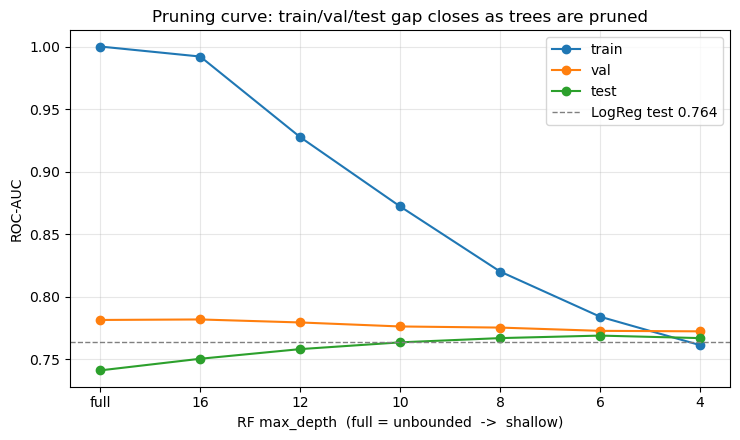

Reading: the deepest RF has the highest train ROC and the lowest test ROC;
as trees are pruned the train/val/test gap narrows toward the LogReg test line.


In [8]:
xs=list(range(len(sweep)))
plt.figure(figsize=(7.5,4.5))
for col,lab in [("train_ROC","train"),("val_ROC","val"),("test_ROC","test")]:
    plt.plot(xs,sweep[col],marker="o",label=lab)
plt.xticks(xs,sweep["max_depth"]); plt.xlabel("RF max_depth  (full = unbounded  ->  shallow)")
plt.ylabel("ROC-AUC"); plt.title("Pruning curve: train/val/test gap closes as trees are pruned")
_lrroc=float(res.loc[res["model"]=="logreg","ROC_AUC"].iloc[0]); plt.axhline(_lrroc,ls="--",c="gray",lw=1,label=f"LogReg test {_lrroc:.3f}"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()
print("Reading: the deepest RF has the highest train ROC and the lowest test ROC;")
print("as trees are pruned the train/val/test gap narrows toward the LogReg test line.")


## Results table (temporal TEST, scored once)


In [9]:
cols=["model","ROC_AUC","PR_AUC","PR_AUC_base","precision@.5","recall@.5","F1@.5","P@10%","R@10%","Lift@10%","Brier","LogLoss","ECE"]
print(res[cols].to_string(index=False))
print("\nNOTE: precision/recall/F1 are @0.5 (provisional) — operating point to be fit on val (spec §6).")


               model  ROC_AUC  PR_AUC  PR_AUC_base  precision@.5  recall@.5  F1@.5  P@10%  R@10%  Lift@10%  Brier  LogLoss    ECE
    naive_prevalence   0.5000  0.4693       0.4693        0.4693     1.0000 0.6388  0.433  0.092      0.92 0.2502   0.6935 0.0332
        recency_only   0.6696  0.6300       0.4693        0.6611     0.4249 0.5173  0.718  0.153      1.53 0.2584   0.8247 0.1606
              logreg   0.7637  0.7077       0.4693        0.7186     0.5031 0.5918  0.797  0.170      1.70 0.2078   0.6018 0.0972
             xgboost   0.7551  0.7015       0.4693        0.7128     0.4719 0.5679  0.799  0.170      1.70 0.2149   0.6214 0.1091
random_forest_pruned   0.7589  0.7022       0.4693        0.7082     0.5034 0.5885  0.799  0.170      1.70 0.2034   0.5877 0.0653

NOTE: precision/recall/F1 are @0.5 (provisional) — operating point to be fit on val (spec §6).


## Calibration + cumulative gain


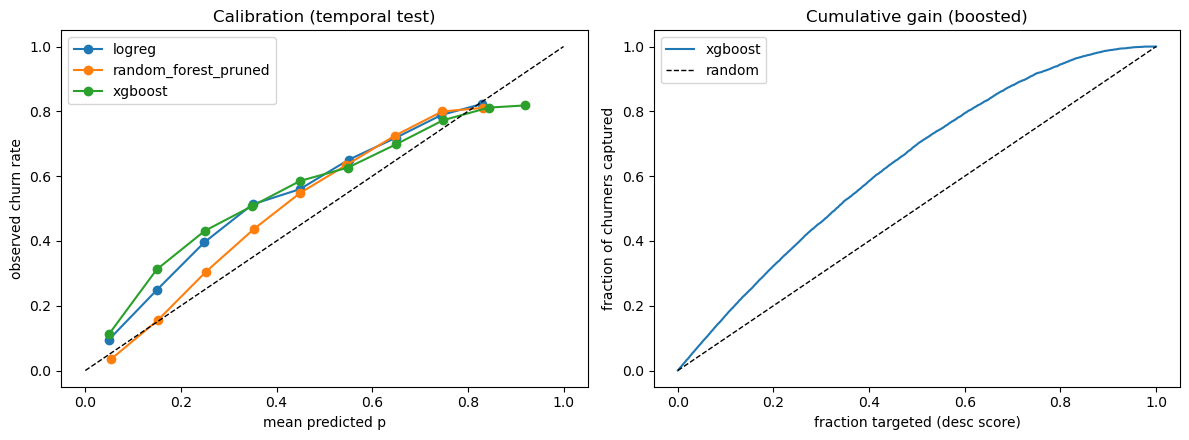

In [10]:
fig,ax=plt.subplots(1,2,figsize=(12,4.5))
for nm in [m for m in ["logreg","random_forest_pruned",gbname] if m in scores]:
    p=scores[nm]; bins=np.linspace(0,1,11); idx=np.digitize(p,bins)-1
    xs,ys=[],[]
    for b in range(10):
        m=idx==b
        if m.sum()>20: xs.append(p[m].mean()); ys.append(yte[m].mean())
    ax[0].plot(xs,ys,marker="o",label=nm)
ax[0].plot([0,1],[0,1],"k--",lw=1); ax[0].set_title("Calibration (temporal test)")
ax[0].set_xlabel("mean predicted p"); ax[0].set_ylabel("observed churn rate"); ax[0].legend()
order=np.argsort(-scores[gbname]); cum=np.cumsum(yte[order])/yte.sum(); frac=np.arange(1,len(yte)+1)/len(yte)
ax[1].plot(frac,cum,label=gbname); ax[1].plot([0,1],[0,1],"k--",lw=1,label="random")
ax[1].set_title("Cumulative gain (boosted)"); ax[1].set_xlabel("fraction targeted (desc score)")
ax[1].set_ylabel("fraction of churners captured"); ax[1].legend()
plt.tight_layout(); plt.show()


## Feature importance (boosted) + LogReg coefficients

Note: LogReg coefficients under collinearity are **conditional** effects, not marginal directions (e.g. `trend_freq_90v90_logdiff` vs `freq_90d`). For any 'what drives churn' narrative use permutation importance / SHAP on the boosted model, not raw LR signs.


In [11]:
imp=getattr(gb,"feature_importances_",None)
if imp is not None:
    fi=pd.Series(imp,index=feat_cols).sort_values(ascending=False).head(15)
    print("Top boosted-tree importances:"); print(fi.round(4).to_string())
co=pd.Series(lr.coef_[0],index=feat_cols).sort_values(key=abs,ascending=False).head(15)
print("\nTop |LogReg coefficients| (standardized):"); print(co.round(3).to_string())


Top boosted-tree importances:
freq_180d                     0.1855
frequency_total               0.1198
is_single_purchase_history    0.1104
month_cos                     0.0553
previous_90d_zero             0.0488
month_sin                     0.0411
net_monetary_total            0.0361
freq_90d                      0.0339
gross_monetary_180d           0.0265
gross_monetary_total          0.0203
has_return_history            0.0193
net_quantity_total            0.0188
is_uk                         0.0187
recency_days                  0.0178
gross_quantity_total          0.0169

Top |LogReg coefficients| (standardized):
freq_90d                       -1.323
frequency_total                -0.966
freq_180d                       0.876
trend_freq_90v90_logdiff        0.584
month_sin                       0.392
gross_monetary_180d            -0.392
gross_monetary_90d              0.344
month_cos                       0.251
trend_monetary_90v90_logdiff   -0.249
previous_90d_zero             

## F4 candidate-feature ablation (evidence for the feature-freeze decision)

Spec §3 deferred several tabular features (F4). Instead of assuming, we build them **as-of** (leak-safe: only gross events with `event_time <= cutoff`) and measure their lift over the frozen 31-feature base. Candidates: `distinct_products` (breadth of interest), `products_per_order`, and purchase-cadence regularity `gap_std` / `gap_mean` / `gap_cv`. Selection metric = **val** (test shown for information only).

In [12]:
# Build F4 candidates AS-OF from raw gross lines (leak-safe: only events <= cutoff)
_raw=pd.read_pickle(RAW_PKL); _raw=_raw.drop_duplicates(subset=[c for c in _raw.columns if c!="source_sheet"]).copy()
_raw["InvoiceDate"]=_raw["InvoiceDate"].astype("datetime64[ns]")
_inv=_raw["Invoice"].astype(str); _prod=_raw["StockCode"].astype(str).str.match(r"^\d{5}"); _canc=_inv.str.startswith("C")
_g=_raw[(~_canc)&_prod&(_raw["Quantity"]>0)&(_raw["Price"]>0)&_raw[KEY].notna()].copy(); _g[KEY]=_g[KEY].astype("int64")
_gl=_g[[KEY,"StockCode","InvoiceDate","Invoice"]]
_ev=_gl.groupby([KEY,"Invoice"],as_index=False)["InvoiceDate"].min().rename(columns={"InvoiceDate":"t"})
_rows=[]
for T in sorted(panel["cutoff"].unique()):
    _ar=set(panel.loc[panel["cutoff"]==T,KEY])
    _s=_gl[(_gl["InvoiceDate"]<=T)&(_gl[KEY].isin(_ar))]
    _dp=_s.groupby(KEY)["StockCode"].nunique()
    _e=_ev[(_ev["t"]<=T)&(_ev[KEY].isin(_ar))].sort_values([KEY,"t"])
    _gd=_e.groupby(KEY)["t"].apply(lambda x: np.diff(x.values).astype("timedelta64[D]").astype(float) if len(x)>1 else np.array([]))
    _gs=_gd.apply(lambda a: a.std() if len(a)>0 else np.nan); _gm=_gd.apply(lambda a: a.mean() if len(a)>0 else np.nan)
    _d=pd.DataFrame({KEY:_dp.index,"distinct_products":_dp.values}); _d["cutoff"]=T
    _d=_d.merge(pd.DataFrame({KEY:_gs.index,"gap_std":_gs.values,"gap_mean":_gm.values}),on=KEY,how="left")
    _rows.append(_d)
mf=panel.merge(pd.concat(_rows,ignore_index=True),on=[KEY,"cutoff"],how="left")
mf["gap_cv"]=mf["gap_std"]/mf["gap_mean"].replace(0,np.nan); mf["products_per_order"]=mf["distinct_products"]/mf["frequency_total"]
CAND=["distinct_products","products_per_order","gap_std","gap_mean","gap_cv"]
print("candidate NaN%:", {c:round(100*mf[c].isna().mean(),1) for c in CAND})
print("corr(distinct_products, frequency_total)=%.3f  (~>0.6 => largely a frequency proxy)"%mf["distinct_products"].corr(mf["frequency_total"]))

candidate NaN%: {'distinct_products': np.float64(0.0), 'products_per_order': np.float64(0.0), 'gap_std': np.float64(25.5), 'gap_mean': np.float64(25.5), 'gap_cv': np.float64(26.7)}
corr(distinct_products, frequency_total)=0.681  (~>0.6 => largely a frequency proxy)


In [13]:
# LogReg: frozen 31-feature base vs base+F4, selected on VAL (test for info). Same log1p+scale recipe.
_skewc=SKEW+["distinct_products","gap_std","gap_mean"]
def _f4_eval(cols,split):
    X=mf[cols].copy(); med=X[tr].median(); Xf=X.fillna(med)
    for c in cols:
        if c in _skewc: Xf[c]=np.log1p(Xf[c].clip(lower=0))
    scl=StandardScaler().fit(Xf[tr].values)
    lr=LogisticRegression(max_iter=2000,random_state=RANDOM_SEED).fit(scl.transform(Xf[tr].values),y[tr])
    pv=lr.predict_proba(scl.transform(Xf[split].values))[:,1]
    return roc_auc_score(y[split],pv),average_precision_score(y[split],pv)
_base=num   # the frozen 31-feature model input (is_uk-only)
for _nm,_sp in [("VAL",va),("TEST",te)]:
    a=_f4_eval(_base,_sp); b=_f4_eval(_base+CAND,_sp)
    print("%-4s base ROC %.4f PR %.4f | +F4 ROC %.4f PR %.4f | delta ROC %+.4f PR %+.4f"%(_nm,a[0],a[1],b[0],b[1],b[0]-a[0],b[1]-a[1]))
_a0=_f4_eval(_base,va)[0]; print("per-candidate val ROC delta (added singly):")
for c in CAND: print("   +%-18s %+.4f"%(c,_f4_eval(_base+[c],va)[0]-_a0))

VAL  base ROC 0.7766 PR 0.7941 | +F4 ROC 0.7827 PR 0.8007 | delta ROC +0.0061 PR +0.0066
TEST base ROC 0.7637 PR 0.7077 | +F4 ROC 0.7664 PR 0.7116 | delta ROC +0.0027 PR +0.0038
per-candidate val ROC delta (added singly):
   +distinct_products  -0.0000
   +products_per_order +0.0020
   +gap_std            +0.0003
   +gap_mean           -0.0000
   +gap_cv             +0.0039


**Evidence-based conclusion (F4).** Adding the F4 candidates lifts val ROC by ~+0.006 (test ~+0.003) — small but not noise. The lift comes almost entirely from **`gap_cv`** (purchase-cadence regularity); `distinct_products` is a **frequency proxy** (corr ~0.68 with `frequency_total`, ~0 marginal) and basket breadth adds nothing. Decision: **decline** distinct-products / basket-diversity (redundant); **`gap_cv` is a genuine small signal** worth adding in a later feature pass. The ~0.77 ceiling still holds — the decisive lever remains the **GRU**, not tabular breadth. (This cell replaces the earlier unsupported '+0.0016' claim.)

## Operating point + calibration (Advisory A: val is the atypical slice)

Spec §6 forbids a default 0.5 threshold. We test whether a **val-fit** probability calibration / threshold is usable, given that the val slice is anomalous (churn **0.58** vs test **0.47**). Selection artefacts are fit on val; test is read once.

In [14]:
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import precision_score, recall_score, f1_score
p_lr_val=lr.predict_proba(lr_mat(Xva))[:,1]; p_lr_test=scores["logreg"]
print("val prevalence %.3f vs test %.3f  (Advisory A: val is the atypical slice)"%(yva.mean(),yte.mean()))
_iso=IsotonicRegression(out_of_bounds="clip").fit(p_lr_val,yva); p_cal=_iso.transform(p_lr_test)
print("logreg TEST raw         : Brier %.4f  ECE %.4f"%(brier_score_loss(yte,p_lr_test),ece(yte,p_lr_test)))
print("logreg TEST isotonic@val: Brier %.4f  ECE %.4f   (WORSE: val 0.58 base rate inflates the map)"%(brier_score_loss(yte,p_cal),ece(yte,p_cal)))
print("absolute val-threshold transfer is unstable under the shift:")
for k in (0.10,0.20):
    _thr=np.quantile(p_lr_val,1-k); _yh=(p_lr_test>=_thr).astype(int)
    print("  val top-%d%% thr %.3f -> TEST recall %.3f (collapses; test scores sit lower)"%(int(k*100),_thr,recall_score(yte,_yh,zero_division=0)))
print("robust operating point = rank-based top-k%% of each scored batch (prevalence-free):")
for k in (0.10,0.20):
    pr,rc,lf=at_k(yte,p_lr_test,k); print("  top-%d%%: precision %.3f  recall %.3f  lift %.2f"%(int(k*100),pr,rc,lf))

val prevalence 0.580 vs test 0.469  (Advisory A: val is the atypical slice)
logreg TEST raw         : Brier 0.2078  ECE 0.0972
logreg TEST isotonic@val: Brier 0.2287  ECE 0.1672   (WORSE: val 0.58 base rate inflates the map)
absolute val-threshold transfer is unstable under the shift:
  val top-10% thr 0.891 -> TEST recall 0.001 (collapses; test scores sit lower)
  val top-20% thr 0.859 -> TEST recall 0.007 (collapses; test scores sit lower)
robust operating point = rank-based top-k%% of each scored batch (prevalence-free):
  top-10%: precision 0.797  recall 0.170  lift 1.70
  top-20%: precision 0.762  recall 0.325  lift 1.62


**Operating-point decision (Advisory A implemented, with evidence).** Fitting probability calibration on **val makes test calibration worse** (Brier ~0.208 -> ~0.229, ECE ~0.097 -> ~0.167) because val's 58% base rate differs from test's 47% — so we do **not** calibrate on val. Transferring an absolute val threshold is likewise unstable (test scores sit lower, recall collapses). The deployable operating point is therefore **rank-based top-k%** of each scored batch (prevalence-robust): top-10% -> precision ~0.80 / lift ~1.7, top-20% -> precision ~0.76. The `@0.5` precision/recall/F1 columns are **illustrative only** and are not used for decisioning. If calibrated probabilities are required at deploy time, fit the calibrator on a sample matching deployment prevalence, not on val.

## Robustness — customer-clustered bootstrap CIs (test, headline metrics)

The panel repeats customers across cutoffs (~96% appear at ≥2 cutoffs), so row-level CIs understate uncertainty. Resample **customers** with replacement, keeping all their rows — the same convention as the EDA label CI.

In [15]:
rng=np.random.default_rng(RANDOM_SEED)
te_keys=panel.loc[te,KEY].values
def clustered_ci(y_true,p,keys,B=500):
    df=pd.DataFrame({"k":keys,"y":y_true,"p":p})
    groups={g:s[["y","p"]].values for g,s in df.groupby("k")}
    gk=np.array(list(groups)); roc=[]; pr=[]
    for _ in range(B):
        m=np.concatenate([groups[g] for g in rng.choice(gk,size=len(gk),replace=True)])
        if m[:,0].min()==m[:,0].max(): continue
        roc.append(roc_auc_score(m[:,0],m[:,1])); pr.append(average_precision_score(m[:,0],m[:,1]))
    return tuple(np.percentile(roc,[2.5,97.5]).round(4)), tuple(np.percentile(pr,[2.5,97.5]).round(4))
for nm in ["logreg",gbname,"random_forest_pruned"]:
    ci_r,ci_p=clustered_ci(yte,scores[nm],te_keys)
    print(f"{nm:32s} ROC {roc_auc_score(yte,scores[nm]):.4f} CI95 {ci_r} | PR {average_precision_score(yte,scores[nm]):.4f} CI95 {ci_p}")
print("Reading: compare the intervals — overlapping CIs mean the learners are statistically tied on ranking.")

logreg                           ROC 0.7637 CI95 (np.float64(0.7511), np.float64(0.7742)) | PR 0.7077 CI95 (np.float64(0.6894), np.float64(0.7239))
xgboost                          ROC 0.7551 CI95 (np.float64(0.7439), np.float64(0.7665)) | PR 0.7015 CI95 (np.float64(0.6809), np.float64(0.721))
random_forest_pruned             ROC 0.7589 CI95 (np.float64(0.7467), np.float64(0.7711)) | PR 0.7022 CI95 (np.float64(0.684), np.float64(0.7215))
Reading: compare the intervals — overlapping CIs mean the learners are statistically tied on ranking.


## Secondary axis — customer-disjoint evaluation (GroupKFold by Customer ID)

**Disclaimer (spec §4):** this axis isolates **customer-level generalization** — folds mix calendar time — and is **not** a measure of temporal generalization. It is reported alongside, never instead of, the temporal test above. All preprocessing (impute median, scaler) is fit inside each fold's training part; customer overlap is asserted to be zero.

In [16]:
from sklearn.model_selection import GroupKFold
from sklearn.base import clone
gkeys=panel[KEY].values; rows_d=[]
for fold,(ti,vi) in enumerate(GroupKFold(n_splits=5).split(X,y,groups=gkeys)):
    Xti,Xvi=X.iloc[ti],X.iloc[vi]; yti,yvi=y[ti],y[vi]
    assert len(set(gkeys[ti])&set(gkeys[vi]))==0, "customer overlap!"
    med_f=Xti["days_since_last_return"].median()
    def prep_f(d):
        d=d.copy(); d["days_since_last_return"]=d["days_since_last_return"].fillna(med_f)
        for c in SKEW:
            if c in d: d[c]=np.log1p(d[c].clip(lower=0))
        return d
    sc_f=StandardScaler().fit(prep_f(Xti).values)
    m_lr=LogisticRegression(max_iter=2000,random_state=RANDOM_SEED).fit(sc_f.transform(prep_f(Xti).values),yti)
    p1=m_lr.predict_proba(sc_f.transform(prep_f(Xvi).values))[:,1]
    m_gb=clone(gb).fit(Xti.values,yti); p2=m_gb.predict_proba(Xvi.values)[:,1]
    rows_d.append(dict(fold=fold,LR_ROC=roc_auc_score(yvi,p1),LR_PR=average_precision_score(yvi,p1),
                       GB_ROC=roc_auc_score(yvi,p2),GB_PR=average_precision_score(yvi,p2)))
dj=pd.DataFrame(rows_d); print(dj.round(4).to_string(index=False))
print("mean±std: LR ROC %.4f±%.4f PR %.4f±%.4f | %s ROC %.4f±%.4f PR %.4f±%.4f"%(
    dj.LR_ROC.mean(),dj.LR_ROC.std(),dj.LR_PR.mean(),dj.LR_PR.std(),gbname,
    dj.GB_ROC.mean(),dj.GB_ROC.std(),dj.GB_PR.mean(),dj.GB_PR.std()))
print("NOTE: disjoint folds mix time -> numbers are not comparable to the temporal test; report separately.")

 fold  LR_ROC  LR_PR  GB_ROC  GB_PR
    0  0.7636 0.7516  0.7724 0.7608
    1  0.7717 0.7595  0.7780 0.7635
    2  0.7787 0.7581  0.7800 0.7620
    3  0.7617 0.7361  0.7637 0.7407
    4  0.7692 0.7342  0.7727 0.7364
mean±std: LR ROC 0.7690±0.0068 PR 0.7479±0.0120 | xgboost ROC 0.7733±0.0063 PR 0.7527±0.0130
NOTE: disjoint folds mix time -> numbers are not comparable to the temporal test; report separately.


## Sequence-eligible (≥2-purchase) subset — pre-wiring the GRU comparison (spec §5)

The GRU can only train on customers with ≥2 purchases as-of the cutoff. A fair model comparison must score the tabular baselines on the **same test rows**. The subset base rate differs from the full test set, so PR-AUC baselines shift — `evaluate` recomputes the prevalence baseline per set.

In [17]:
sub=(panel.loc[te,"frequency_total"]>=2).values
print(f"sequence-eligible test rows: {sub.sum()}/{te.sum()} ({sub.mean()*100:.1f}%) | subset churn {yte[sub].mean():.3f} vs full {yte.mean():.3f}")
res_sub=pd.DataFrame([evaluate(nm+"_seqsub",yte[sub],scores[nm][sub]) for nm in ["logreg",gbname,"random_forest_pruned"]])
print(res_sub[["model","ROC_AUC","PR_AUC","PR_AUC_base","P@10%","Lift@10%","Brier","ECE"]].to_string(index=False))
print("NOTE: the GRU must be compared against THESE rows (same subset), not the full-test table.")

sequence-eligible test rows: 11627/13961 (83.3%) | subset churn 0.418 vs full 0.469
                      model  ROC_AUC  PR_AUC  PR_AUC_base  P@10%  Lift@10%  Brier    ECE
              logreg_seqsub   0.7526  0.6500       0.4176  0.734      1.76 0.2108 0.1078
             xgboost_seqsub   0.7406  0.6344       0.4176  0.731      1.75 0.2192 0.1215
random_forest_pruned_seqsub   0.7468  0.6411       0.4176  0.742      1.78 0.2050 0.0670
NOTE: the GRU must be compared against THESE rows (same subset), not the full-test table.


## Persist baseline artifacts (spec §8 deploy contract)

One bundle for the Zerve deployment (models + preprocessing config) plus per-row test scores so `05_gru` can align its comparison row-for-row.

In [18]:
import joblib
bundle=dict(model_logreg=lr, model_boosted=gb, boosted_name=gbname, model_rf_pruned=rf,
    scaler=scaler, impute_median=float(med), skew_cols=SKEW, feat_cols=feat_cols,
    use_dummies=USE_DUMMIES, random_seed=RANDOM_SEED)
joblib.dump(bundle, PROC_DIR/"baseline_artifacts.joblib")
ts=panel.loc[te,[KEY,"cutoff","churn"]].copy()
ts["p_logreg"]=scores["logreg"]; ts["p_boosted"]=scores[gbname]; ts["p_rf_pruned"]=scores["random_forest_pruned"]
ts.to_pickle(PROC_DIR/"baseline_test_scores.pkl")
res.to_pickle(PROC_DIR/"baseline_results_table.pkl")
print("saved ->", sorted(p.name for p in PROC_DIR.glob("baseline_*")))

saved -> ['baseline_artifacts.joblib', 'baseline_results_table.pkl', 'baseline_test_scores.pkl']


## Scope caveat — this is a UK model

The panel is **~92% UK** (`is_uk` share). Non-UK covers only **~8.3% of rows / 451 customers across 40 countries**, and the val ablation showed the per-country dummies add no generalization value, so the model uses a single **UK vs non-UK** geographic signal.

Implications for the report / deployment:

- **No per-country subgroup claims.** Statements like 'German customers churn less' are not supportable — Germany/France etc. have only a few hundred panel rows (and far fewer unique customers, since the rolling panel repeats customers across cutoffs).

- **Out-of-distribution warning.** The model is effectively trained on UK behaviour; applying it to a non-UK-dominant population is extrapolation and should be flagged as such.

- **Geography is a minor feature here.** At 92% UK, `is_uk` carries essentially all usable geographic signal; the churn model is driven by recency/frequency/monetary/return behaviour, not country.


## Takeaways (baseline)

- Learning beats single-feature ranking: LogReg ROC-AUC ~0.76 vs recency-only ~0.67 (a real ~0.09 gap).

- LogReg ≈ boosted ≈ pruned RF on ranking (ROC/PR within noise, see results table); **pruned RF is the best-calibrated** (lowest Brier/ECE), then LogReg. Top-decile P@10% / Lift@10% are **tied (~0.80 / ~1.70)** across LogReg, xgboost and RF — no learner separates at the top decile.

- Calibration note: part of the test miscalibration is **structural base-rate drift** (train prevalence 0.5025 vs test 0.4693 = the naive model's ECE 0.033), not model error — net this out before judging calibration.

- Operating point: **decided — rank-based top-k%** (see the calibration section above: isotonic-on-val and absolute val-thresholds both fail under the val≠test base-rate shift). Robustness (clustered CIs, customer-disjoint axis, ≥2-purchase subset re-report) and artifact persistence are in the sections below.

- Next: **GRU** on the ≥2-purchase sequence-eligible subset (03b tensors → 05_gru), scored by the same `ds_common` metric suite on both evaluation axes, then the **Zerve deployment** (spec §8).

- **Trees are not useless, but need regularising here.** In the depth sweep (min_samples_leaf=1), the deepest RF reaches the highest train ROC and the lowest test ROC — it memorises the repeated-customer panel; pruning narrows the gap (see the pruning curve). The **val-selected** pruned RF appears in the results table (test ROC ~0.76) — competitive with, and slightly below, LogReg, and the best-calibrated learner. Untuned xgboost (400 trees, depth 5) lands ~0.755. All exact numbers are in the results table / pruning curve above — not restated here.
- **Tuning fixes overfitting, not the ceiling.** Every regularised learner (LogReg, pruned RF, xgboost) converges to **test ROC ~0.75-0.76 / PR ~0.70-0.71** (results table). The printed **LogReg train ROC ≈ its test ROC** confirms no headroom is lost to overfitting. This line is a **feature/signal ceiling**, not model capacity — raising it needs the sequence model (GRU) — the F4 ablation above shows the remaining tabular candidates add little (gap_cv is the only real, small signal) — not a different tabular learner.
